In [6]:
import pandas as pd
import numpy as np

df = pd.read_csv('Dataset.csv')
print(df.info())
print(df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9551 entries, 0 to 9550
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Restaurant ID         9551 non-null   int64  
 1   Restaurant Name       9551 non-null   object 
 2   Country Code          9551 non-null   int64  
 3   City                  9551 non-null   object 
 4   Address               9551 non-null   object 
 5   Locality              9551 non-null   object 
 6   Locality Verbose      9551 non-null   object 
 7   Longitude             9551 non-null   float64
 8   Latitude              9551 non-null   float64
 9   Cuisines              9542 non-null   object 
 10  Average Cost for two  9551 non-null   int64  
 11  Currency              9551 non-null   object 
 12  Has Table booking     9551 non-null   object 
 13  Has Online delivery   9551 non-null   object 
 14  Is delivering now     9551 non-null   object 
 15  Switch to order menu 

In [7]:
X = df.drop(columns=['Aggregate rating'])
y = df['Aggregate rating']
X = pd.get_dummies(X, drop_first=True) # One-Hot Encoding for remaining categorical features

In [8]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [9]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)
print("LR MSE:", mean_squared_error(y_test, y_pred_lr))
print("LR R2:", r2_score(y_test, y_pred_lr))

LR MSE: 0.09190107244548092
LR R2: 0.959623606410436


In [10]:
from sklearn.tree import DecisionTreeRegressor
dt = DecisionTreeRegressor(random_state=42)
dt.fit(X_train, y_train)
y_pred_dt = dt.predict(X_test)
print("DT MSE:", mean_squared_error(y_test, y_pred_dt))
print("DT R2:", r2_score(y_test, y_pred_dt))

DT MSE: 0.049267399267399266
DT R2: 0.9783545517911687


/tmp/ipykernel_593/698948426.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=feat_df, palette='viridis')


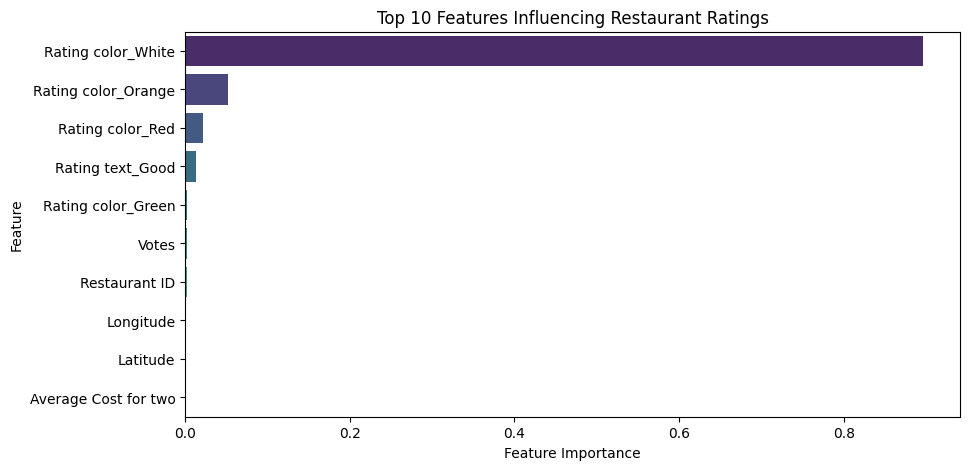

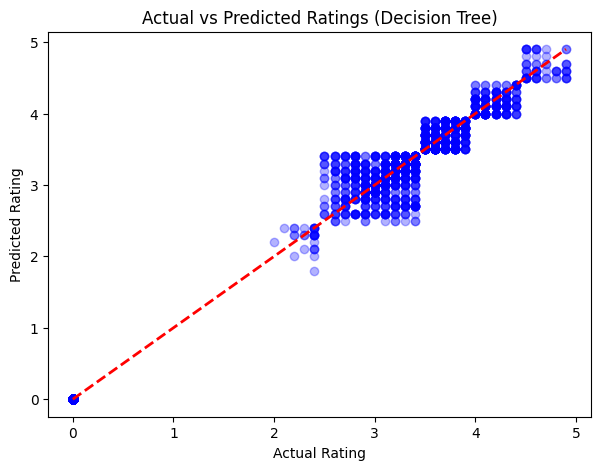

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Feature Importance nikaal kar plot karna
importances = dt.feature_importances_
feature_names = X.columns

feat_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
feat_df = feat_df.sort_values(by='Importance', ascending=False).head(10)

plt.figure(figsize=(10, 5))
sns.barplot(x='Importance', y='Feature', data=feat_df, palette='viridis')
plt.title('Top 10 Features Influencing Restaurant Ratings')
plt.xlabel('Feature Importance')
plt.ylabel('Feature')
plt.show()

# 2. Actual vs Predicted Ratings ka Comparison Scatter Plot
plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred_dt, alpha=0.3, color='blue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel('Actual Rating')
plt.ylabel('Predicted Rating')
plt.title('Actual vs Predicted Ratings (Decision Tree)')
plt.show()